In [11]:
import pandas as pd
import pyodbc

conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    r"SERVER=DESKTOP-U980LH4\SQLEXPRESS;"
    "DATABASE=TaskDB;"
    "Trusted_Connection=yes;"
    "TrustServerCertificate=yes;"
)

df = pd.read_sql("SELECT TOP 5 * FROM sales", conn)
df

C:\Users\start\AppData\Local\Temp\ipykernel_11044\1719628549.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT TOP 5 * FROM sales", conn)


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.959991
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.940002
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.620000
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.577515
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368000


C:\Users\start\AppData\Local\Temp\ipykernel_11044\3032493697.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  cat = pd.read_sql(query1, conn)


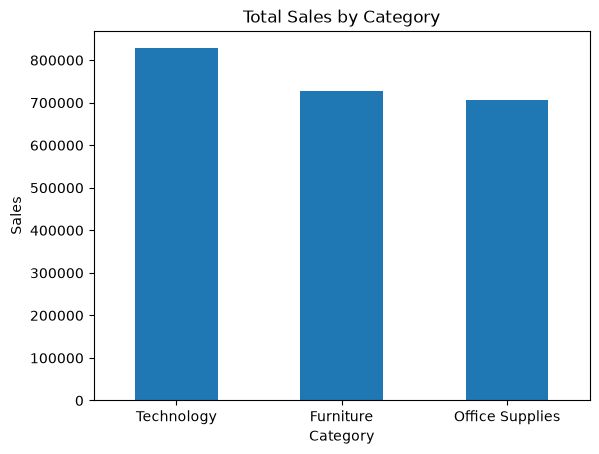

In [12]:
import matplotlib.pyplot as plt

query1 = """
SELECT Category, ROUND(SUM(Sales), 2) AS Total_Sales
FROM sales
GROUP BY Category
ORDER BY Total_Sales DESC;
"""
cat = pd.read_sql(query1, conn)

cat.plot(kind="bar", x="Category", y="Total_Sales", legend=False)
plt.title("Total Sales by Category")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.show()

C:\Users\start\AppData\Local\Temp\ipykernel_11044\3738506630.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top = pd.read_sql(query2, conn)


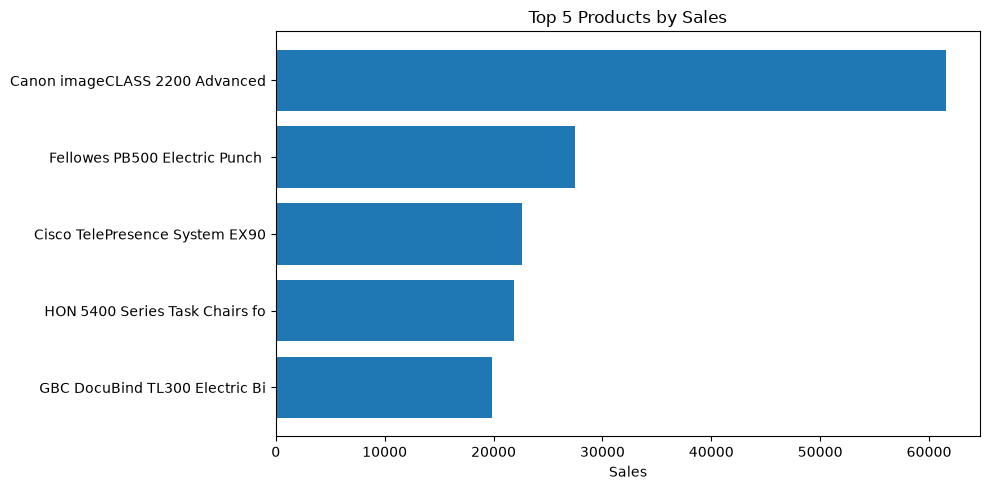

                                        Product_Name  Total_Sales
0              Canon imageCLASS 2200 Advanced Copier     61599.82
1  Fellowes PB500 Electric Punch Plastic Comb Bin...     27453.38
2  Cisco TelePresence System EX90 Videoconferenci...     22638.48
3       HON 5400 Series Task Chairs for Big and Tall     21870.58
4         GBC DocuBind TL300 Electric Binding System     19823.48


In [13]:
top = pd.read_sql(query2, conn)
top["Short_Name"] = top["Product_Name"].str[:30]
plt.figure(figsize=(10, 5))
plt.barh(top["Short_Name"], top["Total_Sales"])
plt.title("Top 5 Products by Sales")
plt.xlabel("Sales")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
print(top[["Product_Name", "Total_Sales"]])

C:\Users\start\AppData\Local\Temp\ipykernel_11044\314524617.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  monthly = pd.read_sql(query3, conn)


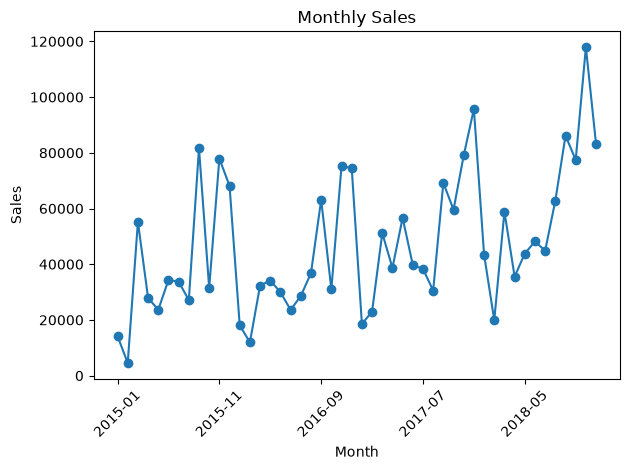

In [14]:
# Monthly sales
query3 = """
SELECT FORMAT(Order_Date, 'yyyy-MM') AS Month,
       ROUND(SUM(Sales), 2) AS Total_Sales
FROM sales
GROUP BY FORMAT(Order_Date, 'yyyy-MM')
ORDER BY Month;
"""
monthly = pd.read_sql(query3, conn)
monthly.plot(kind="line", x="Month", y="Total_Sales", legend=False, marker="o")
plt.title("Monthly Sales")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
df = pd.read_sql("SELECT * FROM sales", conn)
print(df.isnull().sum())

C:\Users\start\AppData\Local\Temp\ipykernel_11044\3612646883.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM sales", conn)


Row_ID            0
Order_ID          0
Order_Date        0
Ship_Date         0
Ship_Mode         0
Customer_ID       0
Customer_Name     0
Segment           0
Country           0
City              0
State             0
Postal_Code      11
Region            0
Product_ID        0
Category          0
Sub_Category      0
Product_Name      0
Sales             0
dtype: int64


In [16]:
df[df["Postal_Code"].isnull()][["City", "State", "Country"]].drop_duplicates()

,City,State,Country
2234,Burlington,Vermont,United States


## الاستنتاجات

- فئة Technology هي الأعلى مبيعًا (حوالي 830 ألف)، وبعدها Furniture ثم Office Supplies، والفرق بين الاتنين الأخيرين صغير.
- المبيعات الشهرية بتزيد من 2015 لـ 2018، وفيه قمم في آخر كل سنة تقريبًا، وأعلى شهر وصل حوالي 120 ألف في أواخر 2018.
- فيه 11 صف في Postal_Code فاضي، كلهم لمدينة Burlington في Vermont، وسبتهم لأنهم قليلين ومش مستخدمين في التحليل.

- منتج Canon imageCLASS 2200 هو الأكثر مبيعًا بفرق كبير (حوالي 58 ألف)، أي أكتر من ضعف المنتج التاني، وباقي الـ Top 5 مبيعاتهم متقاربة.